# Đánh giá và so sánh mô hình phân loại MNIST

Các mô hình:
- Logistic Regression
- Gaussian Naive Bayes
- MLP
- Random Forest
- KNN
- Soft Voting Ensemble: MLP + Random Forest + KNN

Chỉ số đánh giá:
- Accuracy
- Macro Precision, Macro Recall, Macro F1
- Precision, Recall, F1 và Support theo từng lớp
- Confusion matrix
- Thời gian huấn luyện và dự đoán

Validation dùng theo dõi huấn luyện và lựa chọn cấu hình.
Test dùng đánh giá cuối sau khi chốt cấu hình và trọng số ensemble.

In [1]:
from itertools import combinations
from pathlib import Path
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier


SEED = 42
LABELS = np.arange(10)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


from src.preprocessing.scaler import split_val, scale_flat
from src.models.logistic_regression import LogisticRegression
from src.models.naive_bayes import GaussianNaiveBayes
from src.models.mlp import MLP
from src.evaluation.metrics import ClassificationMetrics


DATA_DIR = PROJECT_ROOT / "data" / "raw"

LR_CONFIG = {
    "max_epochs": 26,
    "batch_size": 128,
    "patience": 6,
    "seed": SEED,
    "eta": 0.03,
    "lam": 0.001,
}

NB_SMOOTHING = 0.1

MLP_CONFIG = {
    "sizes": [784, 500, 10],
    "lr": 0.05,
    "momentum": 0.9,
    "p_drop": 0.0,
    "weight_decay": 0.0001,
    "batch_size": 128,
    "max_epochs": 37,
    "patience": 6,
}

RF_CONFIG = {
    "n_estimators": 200,
    "max_depth": None,
    "min_samples_split": 5,
    "random_state": SEED,
    "n_jobs": -1,
}

KNN_CONFIG = {
    "n_neighbors": 3,
    "weights": "distance",
    "metric": "euclidean",
    "n_jobs": -1,
}

# Thứ tự: MLP, Random Forest, KNN.
ENSEMBLE_WEIGHTS = [2.0, 1.0, 1.0]

## 1. Đọc dữ liệu và tiền xử lý

Tách 10% dữ liệu train làm validation.

Sử dụng các hàm tiền xử lý của dự án gốc.
Hàm scale_flat cần fit tham số chuẩn hóa trên train,
sau đó áp dụng cho validation và test.

In [2]:
with np.load(DATA_DIR / "mnist_train.npz") as data:
    X_train_raw = data["X"]
    y_train_raw = data["y"]

with np.load(DATA_DIR / "mnist_test.npz") as data:
    X_test_raw = data["X"]
    y_test = data["y"]

X_train_raw, X_val_raw, y_train, y_val = split_val(
    X=X_train_raw,
    y=y_train_raw,
    val_size=0.1,
    seed=SEED,
)

X_train, X_val, X_test, preprocessing_tools = scale_flat(
    X_train=X_train_raw,
    X_val=X_val_raw,
    X_test=X_test_raw,
    mode="standard",
)

datasets = {
    "Train": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test),
}

split_table = pd.DataFrame(
    [
        {"Split": name, "Samples": len(y)}
        for name, (_, y) in datasets.items()
    ]
)

display(split_table)

Global Mean: 0.1307, Global Std: 0.3082


,Split,Samples
0,Train,54000
1,Validation,6000
2,Test,10000


## 2. Huấn luyện các mô hình đơn

Giữ cấu hình từ notebook gốc.

Mỗi mô hình được huấn luyện một lần.
Ensemble tái sử dụng MLP, Random Forest và KNN đã huấn luyện.

Thời gian train được ghi riêng với thời gian predict.

In [3]:
trained_models = {}
train_times = {}
histories = {}

def timed_fit(model_name, model, fit_function):
    start = time.perf_counter()

    history = fit_function()

    elapsed = time.perf_counter() - start

    trained_models[model_name] = model
    train_times[model_name] = elapsed

    print(f"{model_name}: train {elapsed:.3f} giây")

    return history

## Logistic Regression và Naive Bayes

In [4]:
model_lr = LogisticRegression(**LR_CONFIG)

timed_fit(
    "Logistic Regression",
    model_lr,
    lambda: model_lr.fit(
        X_train,
        y_train,
        X_val=X_val,
        y_val=y_val,
    ),
)

model_nb = GaussianNaiveBayes(
    NB_SMOOTHING,
    batch_size=512,
)

timed_fit(
    "Gaussian Naive Bayes",
    model_nb,
    lambda: model_nb.fit(
        X=X_train,
        y=y_train,
    ),
)

Logistic Regression: train 6.438 giây
Gaussian Naive Bayes: train 0.448 giây


## MLP

In [5]:
model_mlp = MLP(
    sizes=MLP_CONFIG["sizes"],
    activation="relu",
    p_drop=MLP_CONFIG["p_drop"],
    init="he",
    seed=SEED,
)

histories["MLP"] = timed_fit(
    "MLP",
    model_mlp,
    lambda: model_mlp.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=MLP_CONFIG["max_epochs"],
        batch_size=MLP_CONFIG["batch_size"],
        lr=MLP_CONFIG["lr"],
        patience=MLP_CONFIG["patience"],
        weight_decay=MLP_CONFIG["weight_decay"],
        momentum=MLP_CONFIG["momentum"],
        seed=SEED,
        verbose=True,
    ),
)

Epoch 01/37 | train loss 0.0939 acc 0.9697 | val loss 0.1340 acc 0.9590
Epoch 02/37 | train loss 0.0446 acc 0.9865 | val loss 0.1000 acc 0.9718
Epoch 03/37 | train loss 0.0266 acc 0.9919 | val loss 0.0922 acc 0.9733
Epoch 04/37 | train loss 0.0157 acc 0.9962 | val loss 0.0845 acc 0.9748
Epoch 05/37 | train loss 0.0110 acc 0.9972 | val loss 0.0813 acc 0.9807
Epoch 06/37 | train loss 0.0081 acc 0.9983 | val loss 0.0824 acc 0.9797
Epoch 07/37 | train loss 0.0058 acc 0.9993 | val loss 0.0758 acc 0.9812
Epoch 08/37 | train loss 0.0034 acc 0.9998 | val loss 0.0745 acc 0.9810
Epoch 09/37 | train loss 0.0022 acc 1.0000 | val loss 0.0753 acc 0.9827
Epoch 10/37 | train loss 0.0018 acc 1.0000 | val loss 0.0733 acc 0.9832
Epoch 11/37 | train loss 0.0022 acc 0.9999 | val loss 0.0755 acc 0.9828
Epoch 12/37 | train loss 0.0018 acc 1.0000 | val loss 0.0720 acc 0.9837
Epoch 13/37 | train loss 0.0017 acc 1.0000 | val loss 0.0735 acc 0.9832
Epoch 14/37 | train loss 0.0017 acc 1.0000 | val loss 0.0733 acc

## Random Forest và KNN

In [6]:
model_rf = RandomForestClassifier(**RF_CONFIG)

timed_fit(
    "Random Forest",
    model_rf,
    lambda: model_rf.fit(X_train, y_train),
)

model_knn = KNeighborsClassifier(**KNN_CONFIG)

timed_fit(
    "KNN",
    model_knn,
    lambda: model_knn.fit(X_train, y_train),
)

training_table = pd.DataFrame(
    [
        {"Model": name, "Train (s)": elapsed}
        for name, elapsed in train_times.items()
    ]
)

display(
    training_table.style
    .hide(axis="index")
    .format({"Train (s)": "{:.3f}"})
)

Random Forest: train 10.078 giây
KNN: train 0.014 giây


Model,Train (s)
Logistic Regression,6.438
Gaussian Naive Bayes,0.448
MLP,46.816
Random Forest,10.078
KNN,0.014


## 3. Soft Voting Ensemble

Kết hợp xác suất dự đoán của MLP, Random Forest và KNN
với trọng số [2, 1, 1].

Tái sử dụng các mô hình đã fit, không huấn luyện lại.

In [7]:
class CustomSoftVotingEnsemble:
    def __init__(self, models, weights, labels):
        self.models = models
        self.labels = np.asarray(labels)
        self.weights = np.asarray(weights, dtype=float)
        self.weights = self.weights / self.weights.sum()

    def predict_proba(self, X):
        combined = np.zeros((len(X), len(self.labels)))

        with torch.no_grad():
            for weight, model in zip(
                self.weights,
                self.models.values(),
            ):
                proba = model.predict_proba(X)

                if isinstance(proba, torch.Tensor):
                    proba = proba.cpu().numpy()

                combined += weight * proba

        return combined

    def predict(self, X):
        return self.labels[self.predict_proba(X).argmax(axis=1)]


ENSEMBLE_NAME = "Ensemble (MLP + RF + KNN)"

ensemble = CustomSoftVotingEnsemble(
    models={
        "MLP": model_mlp,
        "Random Forest": model_rf,
        "KNN": model_knn,
    },
    weights=ENSEMBLE_WEIGHTS,
    labels=LABELS,
)

trained_models[ENSEMBLE_NAME] = ensemble

ensemble_base_train_seconds = sum(
    train_times[name] for name in ensemble.models
)

print(f"Tổng thời gian train thành phần: {ensemble_base_train_seconds:.3f} giây")

Tổng thời gian train thành phần: 56.907 giây


## 4. Đánh giá trên validation

Import và sử dụng ClassificationMetrics của dự án.

Các chỉ số:
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1

ms/sample là thời gian toàn batch chia số mẫu.

In [8]:
# Lưu kết quả theo khóa: (tên mô hình, tên tập dữ liệu).
evaluations = {}

SCORE_COLUMNS = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
]


def evaluate_model(model, X, y, model_name, split):
    # 1. Dự đoán và đo thời gian.
    start = time.perf_counter()

    with torch.no_grad():
        prediction = model.predict(X)

    if isinstance(prediction, torch.Tensor):
        prediction = prediction.detach().cpu().numpy()

    prediction = np.asarray(prediction)
    predict_time = time.perf_counter() - start

    # 2. Tính các chỉ số đánh giá.
    metrics = ClassificationMetrics(
        y_true=y,
        y_pred=prediction,
        labels=LABELS,
    )

    report = metrics.evaluate()

    # 3. Tạo kết quả tổng hợp cho mô hình.
    summary = {
        "Model": model_name,
        "Split": split,
        "Samples": len(y),
        "Accuracy": report["accuracy"],
        "Macro Precision": report["macro_precision"],
        "Macro Recall": report["macro_recall"],
        "Macro F1": report["macro_f1"],
        "Predict (s)": predict_time,
        "ms/sample": predict_time * 1000 / len(y),
    }

    # 4. Đếm số mẫu thật của từng lớp.
    support = []
    y_true = np.asarray(y)

    for label in LABELS:
        count = np.count_nonzero(y_true == label)
        support.append(count)

    # 5. Tạo bảng đánh giá từng lớp.
    per_class = pd.DataFrame({
        "Class": LABELS,
        "Precision": report["precision"],
        "Recall": report["recall"],
        "F1": report["f1"],
        "Support": support,
    })

    # 6. Lưu để dùng cho bảng so sánh, diversity và heatmap.
    evaluations[(model_name, split)] = {
        "summary": summary,
        "metrics": metrics,
        "prediction": prediction,
        "per_class": per_class,
    }

    return summary


def results_dataframe():
    """Gộp các kết quả tổng hợp thành một bảng."""
    rows = []

    for result in evaluations.values():
        rows.append(result["summary"])

    return pd.DataFrame(rows)


def display_results(frame, highlight=False):
    """Hiển thị phần trăm và thời gian với định dạng dễ đọc."""
    formats = {
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Predict (s)": "{:.3f}",
        "ms/sample": "{:.4f}",
    }

    style = frame.style.format(formats)
    style = style.hide(axis="index")

    if highlight:
        style = style.highlight_max(
            subset=SCORE_COLUMNS,
            color="#04471e",
        )

    display(style)


# Đánh giá từng mô hình trên validation.
validation_rows = []

for name, model in trained_models.items():
    summary = evaluate_model(
        model=model,
        X=X_val,
        y=y_val,
        model_name=name,
        split="Validation",
    )

    validation_rows.append(summary)

# Tạo bảng riêng cho validation.
validation_results = pd.DataFrame(validation_rows)

# Ưu tiên Macro F1 cao; nếu bằng nhau thì xét Accuracy.
validation_results = validation_results.sort_values(
    by=["Macro F1", "Accuracy"],
    ascending=False,
)

validation_results = validation_results.reset_index(drop=True)

display_results(validation_results, highlight=True)

Model,Split,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Predict (s),ms/sample
Ensemble (MLP + RF + KNN),Validation,6000,98.40%,98.40%,98.39%,98.39%,3.516,0.5860
MLP,Validation,6000,98.27%,98.27%,98.26%,98.26%,0.024,0.0040
KNN,Validation,6000,97.23%,97.29%,97.19%,97.23%,3.361,0.5602
Random Forest,Validation,6000,96.70%,96.69%,96.69%,96.68%,0.136,0.0227
Logistic Regression,Validation,6000,92.32%,92.24%,92.24%,92.24%,0.017,0.0028
Gaussian Naive Bayes,Validation,6000,79.60%,81.48%,79.22%,79.49%,0.270,0.0451


## 5. Phân tích diversity trên validation

- Disagreement: tỷ lệ hai mô hình dự đoán khác nhau trên toàn tập.
- Double fault: tỷ lệ cả hai mô hình cùng sai trên toàn tập.
- Conditional double fault: tỷ lệ cả hai cùng sai trong các mẫu
  có ít nhất một mô hình sai.

Disagreement cao không tự bảo đảm ensemble tốt hơn.
Cần xem cùng chất lượng mô hình và kết quả validation.

In [9]:
def measure_diversity(prediction_a, prediction_b, y_true):
    wrong_a = prediction_a != y_true
    wrong_b = prediction_b != y_true

    both_wrong = int(np.sum(wrong_a & wrong_b))
    at_least_one_wrong = int(np.sum(wrong_a | wrong_b))

    return {
        "Disagreement": float(
            np.mean(prediction_a != prediction_b)
        ),
        "Double fault": (
            both_wrong / at_least_one_wrong
            if at_least_one_wrong > 0
            else 0.0
        ),
        "Both wrong count": both_wrong,
        "At least one wrong count": at_least_one_wrong,
    }


diversity_rows = []

for name_a, name_b in combinations(
    ["MLP", "Random Forest", "KNN"],
    2,
):
    result = measure_diversity(
        evaluations[(name_a, "Validation")]["prediction"],
        evaluations[(name_b, "Validation")]["prediction"],
        y_val,
    )

    diversity_rows.append(
        {
            "Model A": name_a,
            "Model B": name_b,
            **result,
        }
    )

diversity_table = pd.DataFrame(diversity_rows)

display(
    diversity_table.style
    .hide(axis="index")
    .format(
        {
            column: "{:.2%}"
            for column in [
                "Disagreement",
                "Double fault",
                "Conditional double fault",
            ]
        }
    )
)

Model A,Model B,Disagreement,Double fault,Both wrong count,At least one wrong count
MLP,Random Forest,2.82%,33.04%,75,227
MLP,KNN,2.53%,33.66%,68,202
Random Forest,KNN,3.45%,31.88%,88,276


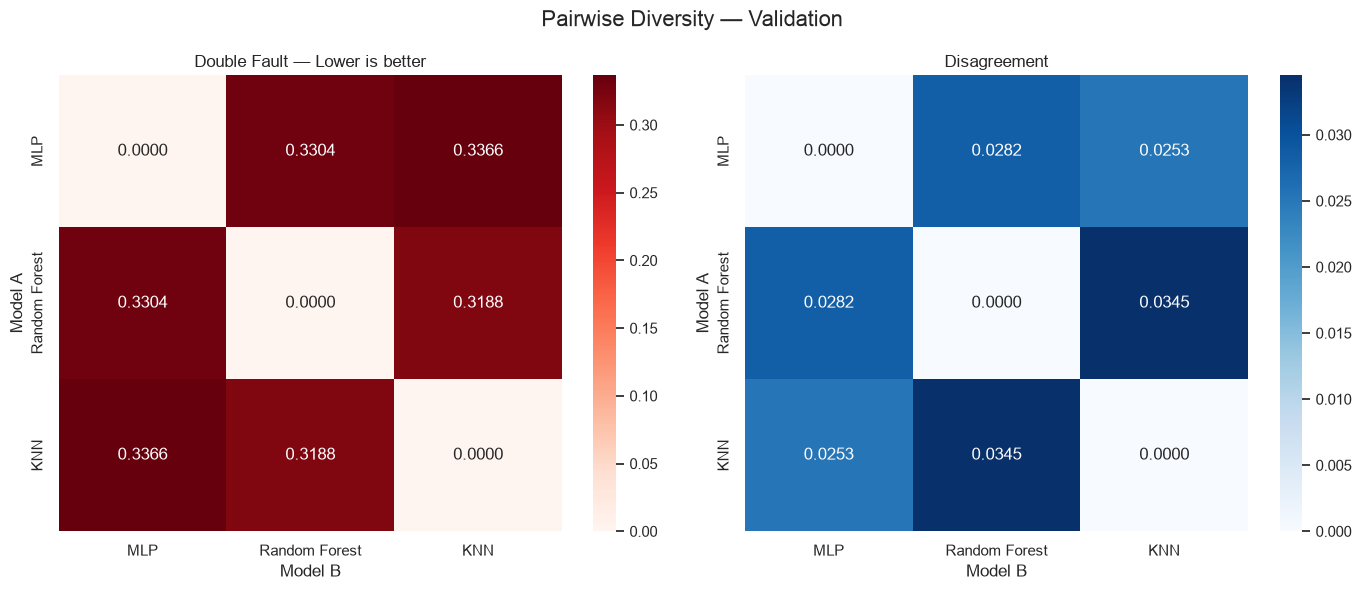

In [10]:
model_names = ["MLP", "Random Forest", "KNN"]

y_preds = [
    evaluations[("MLP", "Validation")]["prediction"],
    evaluations[("Random Forest", "Validation")]["prediction"],
    evaluations[("KNN", "Validation")]["prediction"],
]

n = len(model_names)

double_fault_mat = np.zeros((n, n))
disagreement_mat = np.zeros((n, n))

# Tính diversity giữa từng cặp mô hình.
for i in range(n):
    for j in range(n):
        if i == j:
            continue

        diversity = measure_diversity(
            y_preds[i],
            y_preds[j],
            y_val,
        )

        double_fault_mat[i, j] = diversity["Double fault"]
        disagreement_mat[i, j] = diversity["Disagreement"]

# Vẽ hai heatmap.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Pairwise Diversity — Validation", fontsize=16)

sns.heatmap(
    double_fault_mat,
    annot=True,
    fmt=".4f",
    cmap="Reds",
    xticklabels=model_names,
    yticklabels=model_names,
    ax=axes[0],
)

axes[0].set_title("Double Fault — Lower is better")
axes[0].set_xlabel("Model B")
axes[0].set_ylabel("Model A")

sns.heatmap(
    disagreement_mat,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    xticklabels=model_names,
    yticklabels=model_names,
    ax=axes[1],
)

axes[1].set_title("Disagreement")
axes[1].set_xlabel("Model B")
axes[1].set_ylabel("Model A")

plt.tight_layout()
plt.show()

## 6. Đánh giá cuối trên test

Chỉ chạy sau khi đã chốt cấu hình và trọng số ensemble.

Bảng test giữ thứ tự mô hình theo Macro F1 trên validation.
Không sử dụng test để điều chỉnh lại cấu hình.

Validation đã tham gia early stopping nên không thay thế được
phép đánh giá độc lập trên test.

In [11]:
# 1. Đánh giá trên test theo thứ tự bảng validation.
model_order = validation_results["Model"].tolist()
test_rows = []

for name in model_order:
    summary = evaluate_model(
        model=trained_models[name],
        X=X_test,
        y=y_test,
        model_name=name,
        split="Test",
    )
    test_rows.append(summary)

test_results = pd.DataFrame(test_rows)

print("KẾT QUẢ TRÊN TEST")
display_results(test_results)

all_results = results_dataframe()

# 2. So sánh các chỉ số giữa validation và test.
comparison_rows = []
gap_rows = []

for name in model_order:
    val = evaluations[(name, "Validation")]["summary"]
    test = evaluations[(name, "Test")]["summary"]

    row = {"Model": name}

    for metric in SCORE_COLUMNS:
        row[f"Val {metric}"] = val[metric]
        row[f"Test {metric}"] = test[metric]

    comparison_rows.append(row)

    gap_rows.append({
        "Model": name,
        "Validation": val["Macro F1"],
        "Test": test["Macro F1"],
        "Test - Validation (percentage points)": (
            test["Macro F1"] - val["Macro F1"]
        ) * 100,
    })

val_test_comparison = pd.DataFrame(comparison_rows)
f1_gap = pd.DataFrame(gap_rows)

# 3. Hiển thị bảng so sánh.
formats = {}

for metric in SCORE_COLUMNS:
    formats[f"Val {metric}"] = "{:.2%}"
    formats[f"Test {metric}"] = "{:.2%}"

print("\nSO SÁNH VALIDATION VÀ TEST")
display(val_test_comparison.style.format(formats))

print("\nCHÊNH LỆCH MACRO F1")
display(f1_gap.style.format({
    "Validation": "{:.2%}",
    "Test": "{:.2%}",
    "Test - Validation (percentage points)": "{:+.3f}",
}))

KẾT QUẢ TRÊN TEST


Model,Split,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Predict (s),ms/sample
Ensemble (MLP + RF + KNN),Test,10000,98.48%,98.47%,98.47%,98.47%,5.700,0.5700
MLP,Test,10000,98.35%,98.34%,98.34%,98.34%,0.030,0.0030
KNN,Test,10000,97.09%,97.11%,97.06%,97.07%,5.568,0.5568
Random Forest,Test,10000,96.90%,96.88%,96.87%,96.87%,0.192,0.0192
Logistic Regression,Test,10000,92.54%,92.44%,92.43%,92.43%,0.025,0.0025
Gaussian Naive Bayes,Test,10000,81.49%,83.12%,81.12%,81.33%,0.435,0.0435



SO SÁNH VALIDATION VÀ TEST


,Model,Val Accuracy,Test Accuracy,Val Macro Precision,Test Macro Precision,Val Macro Recall,Test Macro Recall,Val Macro F1,Test Macro F1
0,Ensemble (MLP + RF + KNN),98.40%,98.48%,98.40%,98.47%,98.39%,98.47%,98.39%,98.47%
1,MLP,98.27%,98.35%,98.27%,98.34%,98.26%,98.34%,98.26%,98.34%
2,KNN,97.23%,97.09%,97.29%,97.11%,97.19%,97.06%,97.23%,97.07%
3,Random Forest,96.70%,96.90%,96.69%,96.88%,96.69%,96.87%,96.68%,96.87%
4,Logistic Regression,92.32%,92.54%,92.24%,92.44%,92.24%,92.43%,92.24%,92.43%
5,Gaussian Naive Bayes,79.60%,81.49%,81.48%,83.12%,79.22%,81.12%,79.49%,81.33%



CHÊNH LỆCH MACRO F1


,Model,Validation,Test,Test - Validation (percentage points)
0,Ensemble (MLP + RF + KNN),98.39%,98.47%,+0.077
1,MLP,98.26%,98.34%,+0.079
2,KNN,97.23%,97.07%,-0.157
3,Random Forest,96.68%,96.87%,+0.190
4,Logistic Regression,92.24%,92.43%,+0.192
5,Gaussian Naive Bayes,79.49%,81.33%,+1.831


## 7. Báo cáo từng lớp và confusion matrix

Chọn mô hình và tập dữ liệu cần xem.

Confusion matrix:
- Hàng: nhãn thật.
- Cột: nhãn dự đoán.

Support là số mẫu thật của từng lớp.

Class,Precision,Recall,F1,Support
0,0.9779,0.9949,0.9863,980
1,0.9921,0.9921,0.9921,1135
2,0.9844,0.9797,0.9820,1032
3,0.9842,0.9851,0.9847,1010
4,0.9877,0.9837,0.9857,982
5,0.9843,0.9821,0.9832,892
6,0.9864,0.9875,0.9870,958
7,0.9806,0.9835,0.9820,1028
8,0.9876,0.9795,0.9835,974
9,0.9821,0.9792,0.9806,1009


     Class  Precision     Recall         F1
         0      0.978      0.995      0.986 
         1      0.992      0.992      0.992 
         2      0.984      0.980      0.982 
         3      0.984      0.985      0.985 
         4      0.988      0.984      0.986 
         5      0.984      0.982      0.983 
         6      0.986      0.987      0.987 
         7      0.981      0.983      0.982 
         8      0.988      0.979      0.984 
         9      0.982      0.979      0.981 
 Macro avg      0.985      0.985      0.985 

Accuracy: 0.985


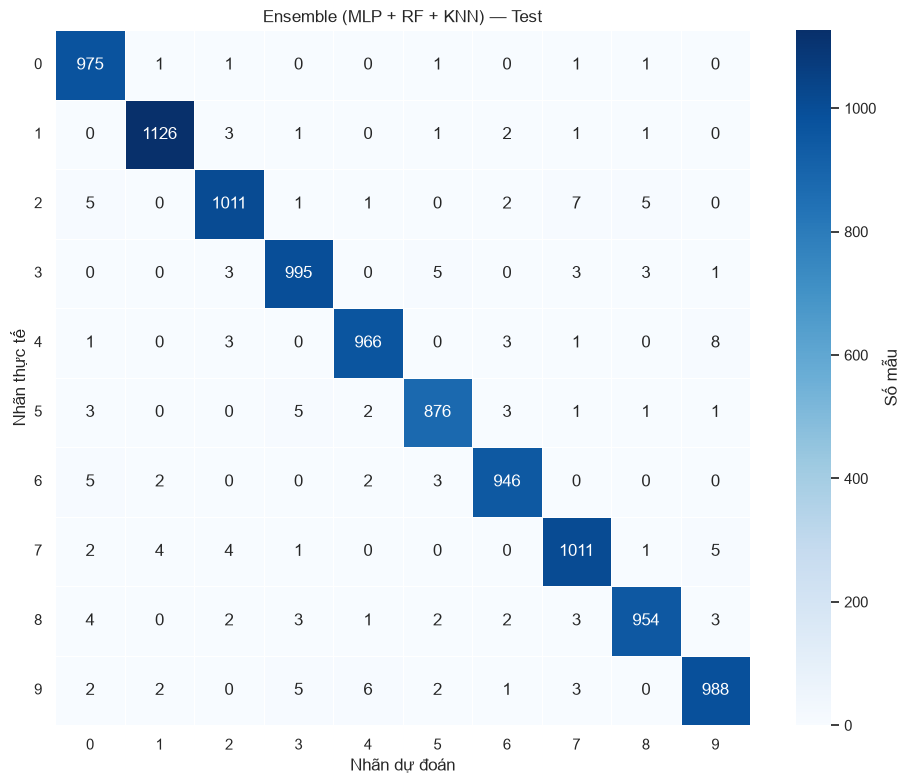

In [12]:
def plot_confusion_matrix(metrics, title):
    cm, labels = metrics.get_confustion_matrix()

    fig, ax = plt.subplots(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt=".0f",
        cmap="Blues",
        square=True,
        xticklabels=labels,
        yticklabels=labels,
        linewidths=0.5,
        cbar_kws={"label": "Số mẫu"},
        ax=ax,
    )

    ax.set(
        title=title,
        xlabel="Nhãn dự đoán",
        ylabel="Nhãn thực tế",
    )
    ax.tick_params(axis="both", labelrotation=0)

    fig.tight_layout()
    plt.show()


MODEL_TO_INSPECT = ENSEMBLE_NAME
SPLIT_TO_INSPECT = "Test" 

selected = evaluations[
    (MODEL_TO_INSPECT, SPLIT_TO_INSPECT)
]

display(
    selected["per_class"].style
    .hide(axis="index")
    .format(
        {
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1": "{:.4f}",
        }
    )
)

selected["metrics"].report()

plot_confusion_matrix(
    selected["metrics"],
    title=f"{MODEL_TO_INSPECT} — {SPLIT_TO_INSPECT}",
)

## 8. Biểu đồ so sánh

So sánh Accuracy và Macro F1 của các mô hình trên validation và test.

Dùng bảng số liệu để đối chiếu giá trị chính xác.

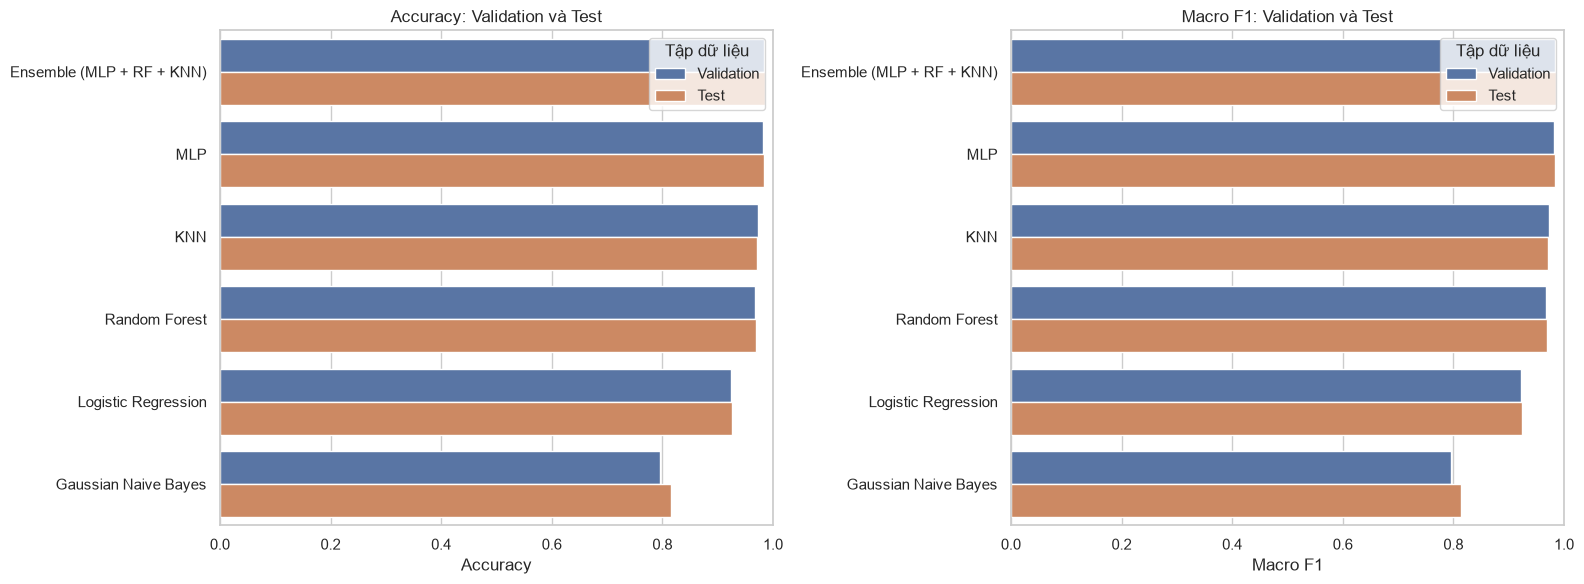

In [13]:
fig, axes = plt.subplots(
    ncols=2,
    figsize=(16, 6),
)

for ax, metric in zip(
    axes,
    ["Accuracy", "Macro F1"],
):
    sns.barplot(
        data=all_results,
        x=metric,
        y="Model",
        hue="Split",
        order=model_order,
        ax=ax,
    )

    ax.set(
        title=f"{metric}: Validation và Test",
        xlabel=metric,
        ylabel="",
        xlim=(0, 1),
    )

    ax.legend(title="Tập dữ liệu")

fig.tight_layout()
plt.show()

## 9. Lịch sử huấn luyện MLP

Vẽ Loss và Accuracy theo epoch.

Sử dụng các khóa lịch sử từ notebook gốc:
train_loss, val_loss, train_acc, val_acc.

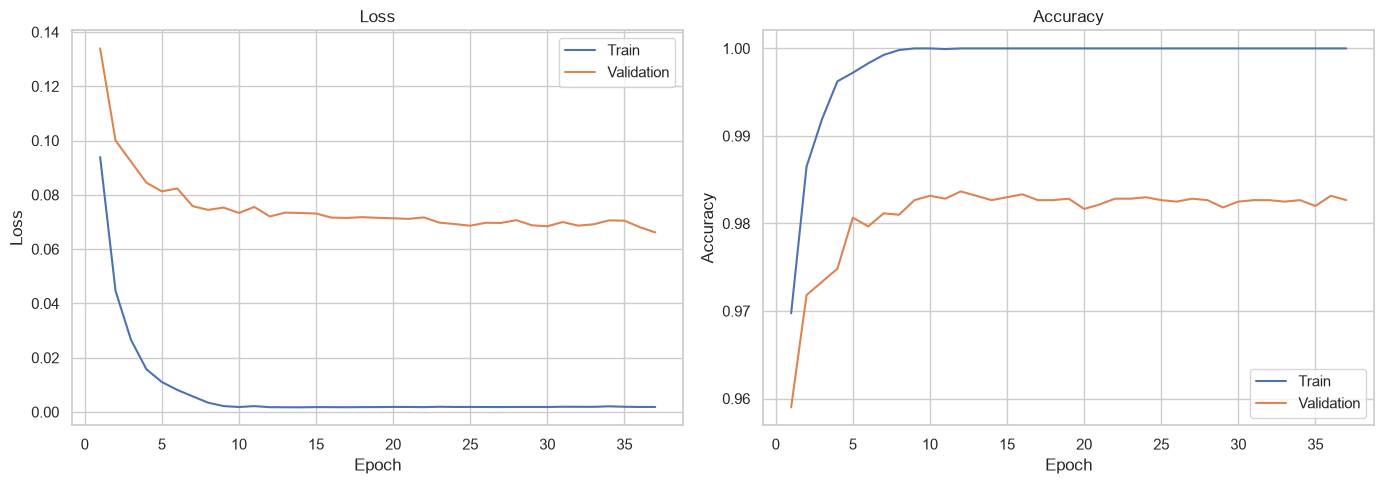

In [14]:
def plot_training_history(history):
    if history is None:
        print("MLP không trả lịch sử huấn luyện.")
        return

    history_df = pd.DataFrame(history)

    required_columns = {
        "train_loss",
        "val_loss",
        "train_acc",
        "val_acc",
    }

    if (
        history_df.empty
        or not required_columns.issubset(history_df.columns)
    ):
        print(
            "Cấu trúc history chưa phù hợp. "
            f"Các cột hiện có: {list(history_df.columns)}"
        )
        return

    history_df["Epoch"] = np.arange(
        1,
        len(history_df) + 1,
    )

    fig, axes = plt.subplots(
        ncols=2,
        figsize=(14, 5),
    )

    plot_configs = [
        ("train_loss", "val_loss", "Loss"),
        ("train_acc", "val_acc", "Accuracy"),
    ]

    for ax, (train_key, val_key, title) in zip(
        axes,
        plot_configs,
    ):
        ax.plot(
            history_df["Epoch"],
            history_df[train_key],
            label="Train",
        )
        ax.plot(
            history_df["Epoch"],
            history_df[val_key],
            label="Validation",
        )

        ax.set(
            title=title,
            xlabel="Epoch",
            ylabel=title,
        )
        ax.legend()

    fig.tight_layout()
    plt.show()


plot_training_history(histories["MLP"])

## 10. Tổng hợp bảng kết quả

Các bảng được giữ trong bộ nhớ:
- all_results: kết quả tổng hợp validation và test.
- val_test_comparison: đối chiếu hai tập.
- per_class_results: kết quả từng lớp của tất cả mô hình.
- training_comparison: thời gian huấn luyện.

Với ensemble:
- Train (s): tổng thời gian train các mô hình thành phần.
- Additional train (s): thời gian train bổ sung, bằng 0 vì tái sử dụng.

In [15]:
per_class_reports = []

for (name, split), item in evaluations.items():
    report = item["per_class"].copy()

    report.insert(0, "Split", split)
    report.insert(0, "Model", name)

    per_class_reports.append(report)

per_class_results = pd.concat(
    per_class_reports,
    ignore_index=True,
)

training_comparison = training_table.copy()

training_comparison["Additional train (s)"] = (
    training_comparison["Train (s)"]
)

training_comparison = pd.concat(
    [
        training_comparison,
        pd.DataFrame(
            [
                {
                    "Model": ENSEMBLE_NAME,
                    "Train (s)": ensemble_base_train_seconds,
                    "Additional train (s)": 0.0,
                }
            ]
        ),
    ],
    ignore_index=True,
)

print("THỜI GIAN HUẤN LUYỆN")
display(
    training_comparison.style
    .hide(axis="index")
    .format(
        {
            "Train (s)": "{:.3f}",
            "Additional train (s)": "{:.3f}",
        }
    )
)

print("\nTOÀN BỘ KẾT QUẢ")
display_results(all_results)

THỜI GIAN HUẤN LUYỆN


Model,Train (s),Additional train (s)
Logistic Regression,6.438,6.438
Gaussian Naive Bayes,0.448,0.448
MLP,46.816,46.816
Random Forest,10.078,10.078
KNN,0.014,0.014
Ensemble (MLP + RF + KNN),56.907,0.000



TOÀN BỘ KẾT QUẢ


Model,Split,Samples,Accuracy,Macro Precision,Macro Recall,Macro F1,Predict (s),ms/sample
Logistic Regression,Validation,6000,92.32%,92.24%,92.24%,92.24%,0.017,0.0028
Gaussian Naive Bayes,Validation,6000,79.60%,81.48%,79.22%,79.49%,0.270,0.0451
MLP,Validation,6000,98.27%,98.27%,98.26%,98.26%,0.024,0.0040
Random Forest,Validation,6000,96.70%,96.69%,96.69%,96.68%,0.136,0.0227
KNN,Validation,6000,97.23%,97.29%,97.19%,97.23%,3.361,0.5602
Ensemble (MLP + RF + KNN),Validation,6000,98.40%,98.40%,98.39%,98.39%,3.516,0.5860
Ensemble (MLP + RF + KNN),Test,10000,98.48%,98.47%,98.47%,98.47%,5.700,0.5700
MLP,Test,10000,98.35%,98.34%,98.34%,98.34%,0.030,0.0030
KNN,Test,10000,97.09%,97.11%,97.06%,97.07%,5.568,0.5568
Random Forest,Test,10000,96.90%,96.88%,96.87%,96.87%,0.192,0.0192


## Lưu trọng số mô hình Ensemble

Lưu các thành phần:
- `mlp_part.pth`: trọng số và cấu hình MLP.
- `rf_part.joblib`: Random Forest.
- `knn_part.joblib`: KNN.
- `config.json`: trọng số voting, thứ tự mô hình và nhãn lớp.

Ensemble tái sử dụng các mô hình đã huấn luyện nên không cần train lại.

In [16]:
import json
import joblib
import torch


ENSEMBLE_DIR = PROJECT_ROOT / "models" / "ensemble_v1"
ENSEMBLE_DIR.mkdir(parents=True, exist_ok=True)

mlp_part = ensemble.models["MLP"]
rf_part = ensemble.models["Random Forest"]
knn_part = ensemble.models["KNN"]

# 1. Lưu trọng số và cấu hình MLP.
torch.save(
    {
        "model_state_dict": mlp_part.model.state_dict(),
        "config": {
            "sizes": MLP_CONFIG["sizes"],
            "activation": "relu",
            "p_drop": MLP_CONFIG["p_drop"],
            "init": "he",
            "seed": SEED,
        },
    },
    ENSEMBLE_DIR / "mlp_part.pth",
)

# 2. Lưu Random Forest và KNN.
joblib.dump(rf_part, ENSEMBLE_DIR / "rf_part.joblib")
joblib.dump(knn_part, ENSEMBLE_DIR / "knn_part.joblib")

# 3. Lưu cấu hình voting.
# ensemble.weights trong class đơn giản đã được chuẩn hóa.
config = {
    "weights": ensemble.weights.tolist(),
    "model_order": list(ensemble.models),
    "labels": ensemble.labels.tolist(),
}

with (ENSEMBLE_DIR / "config.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

print(f"Đã lưu Ensemble tại: {ENSEMBLE_DIR}")

Đã lưu Ensemble tại: /home/nguyenhaianh/Desktop/Classify_Number/models/ensemble_v1
